In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd()
if not (ROOT / "src").is_dir():
    ROOT = ROOT.parent

if not (ROOT / "src").is_dir():
    raise RuntimeError("Open this notebook inside the project folder.")

sys.path.insert(0, str(ROOT / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from process_data import load_measurements, summarize_measurements
from visualize import create_figures

print("Python:", sys.executable)
print("Project folder:", ROOT)
print("Imports OK")

Python: /opt/anaconda3/envs/shortform-study/bin/python
Project folder: /Users/nurayaben/shortform-video-procrastination-study
Imports OK


In [2]:
log_path = ROOT / "data/raw/comparison_run.jsonl"

raw = pd.read_json(log_path, lines=True)
measured = load_measurements(log_path)

print("Всего записей:", len(raw))
print("Прогревочных:", (raw["phase"] == "warmup").sum())
print("Рабочих:", len(measured))

display(
    measured.groupby(["method", "input_rows"])
    .agg(
        total_runs=("success", "size"),
        successful_runs=("success", "sum"),
    )
    .assign(
        failed_runs=lambda table:
        table["total_runs"] - table["successful_runs"]
    )
)

Всего записей: 880
Прогревочных: 80
Рабочих: 800


total_runs  successful_runs  failed_runs
method   input_rows                                          
baseline 10                 100              100            0
         100                100              100            0
         1000               100              100            0
         10000              100              100            0
proposed 10                 100              100            0
         100                100              100            0
         1000               100              100            0
         10000              100              100            0

In [3]:
summary = summarize_measurements(
    measured,
    seed=42,
    n_bootstrap=5000,
)

output_path = ROOT / "data/processed/metrics_summary.csv"
output_path.parent.mkdir(parents=True, exist_ok=True)
summary.to_csv(output_path, index=False)

display_columns = [
    "method",
    "input_rows",
    "mean_ms",
    "sd_ms",
    "median_ms",
    "p25_ms",
    "p75_ms",
    "p95_ms",
    "p99_ms",
    "median_ci_low_ms",
    "median_ci_high_ms",
    "error_rate",
]

display(summary[display_columns].round(4))
print("Saved:", output_path)

,method,input_rows,mean_ms,sd_ms,median_ms,p25_ms,p75_ms,p95_ms,p99_ms,median_ci_low_ms,median_ci_high_ms,error_rate
0,baseline,10,3.5438,0.0353,3.5366,3.5166,3.5708,3.5910,3.6163,3.5281,3.5472,0.0
1,baseline,100,3.6401,0.0275,3.6345,3.6217,3.6578,3.6918,3.7040,3.6286,3.6390,0.0
2,baseline,1000,5.1825,0.3439,5.0156,4.9915,5.1712,5.9045,6.3276,5.0056,5.0352,0.0
3,baseline,10000,21.3966,3.9552,20.6474,20.4810,21.0246,22.5782,32.9788,20.5763,20.6848,0.0
4,proposed,10,1.9155,0.0222,1.9105,1.9032,1.9200,1.9604,1.9650,1.9085,1.9130,0.0
5,proposed,100,1.9321,0.0198,1.9295,1.9212,1.9379,1.9743,1.9884,1.9253,1.9318,0.0
6,proposed,1000,2.2663,0.1612,2.1934,2.1761,2.2907,2.5739,2.8044,2.1845,2.2033,0.0
7,proposed,10000,5.0390,1.1017,4.8520,4.7972,4.9751,5.5083,5.8650,4.8309,4.8929,0.0


Saved: /Users/nurayaben/shortform-video-procrastination-study/data/processed/metrics_summary.csv


### Statistical summary

Warm-up runs are excluded. Execution-time statistics are calculated
for successful measured runs; failures remain included in the error rate.

The table reports mean, sample SD, median, quartiles, p95 and p99.
Bootstrap 95% confidence intervals use 5,000 resamples with seed 42.

These intervals describe within-session timing uncertainty under an
independent-run assumption. They do not capture variation across
machines or separate sessions. With 100 measurements per group,
p99 estimates are approximate.

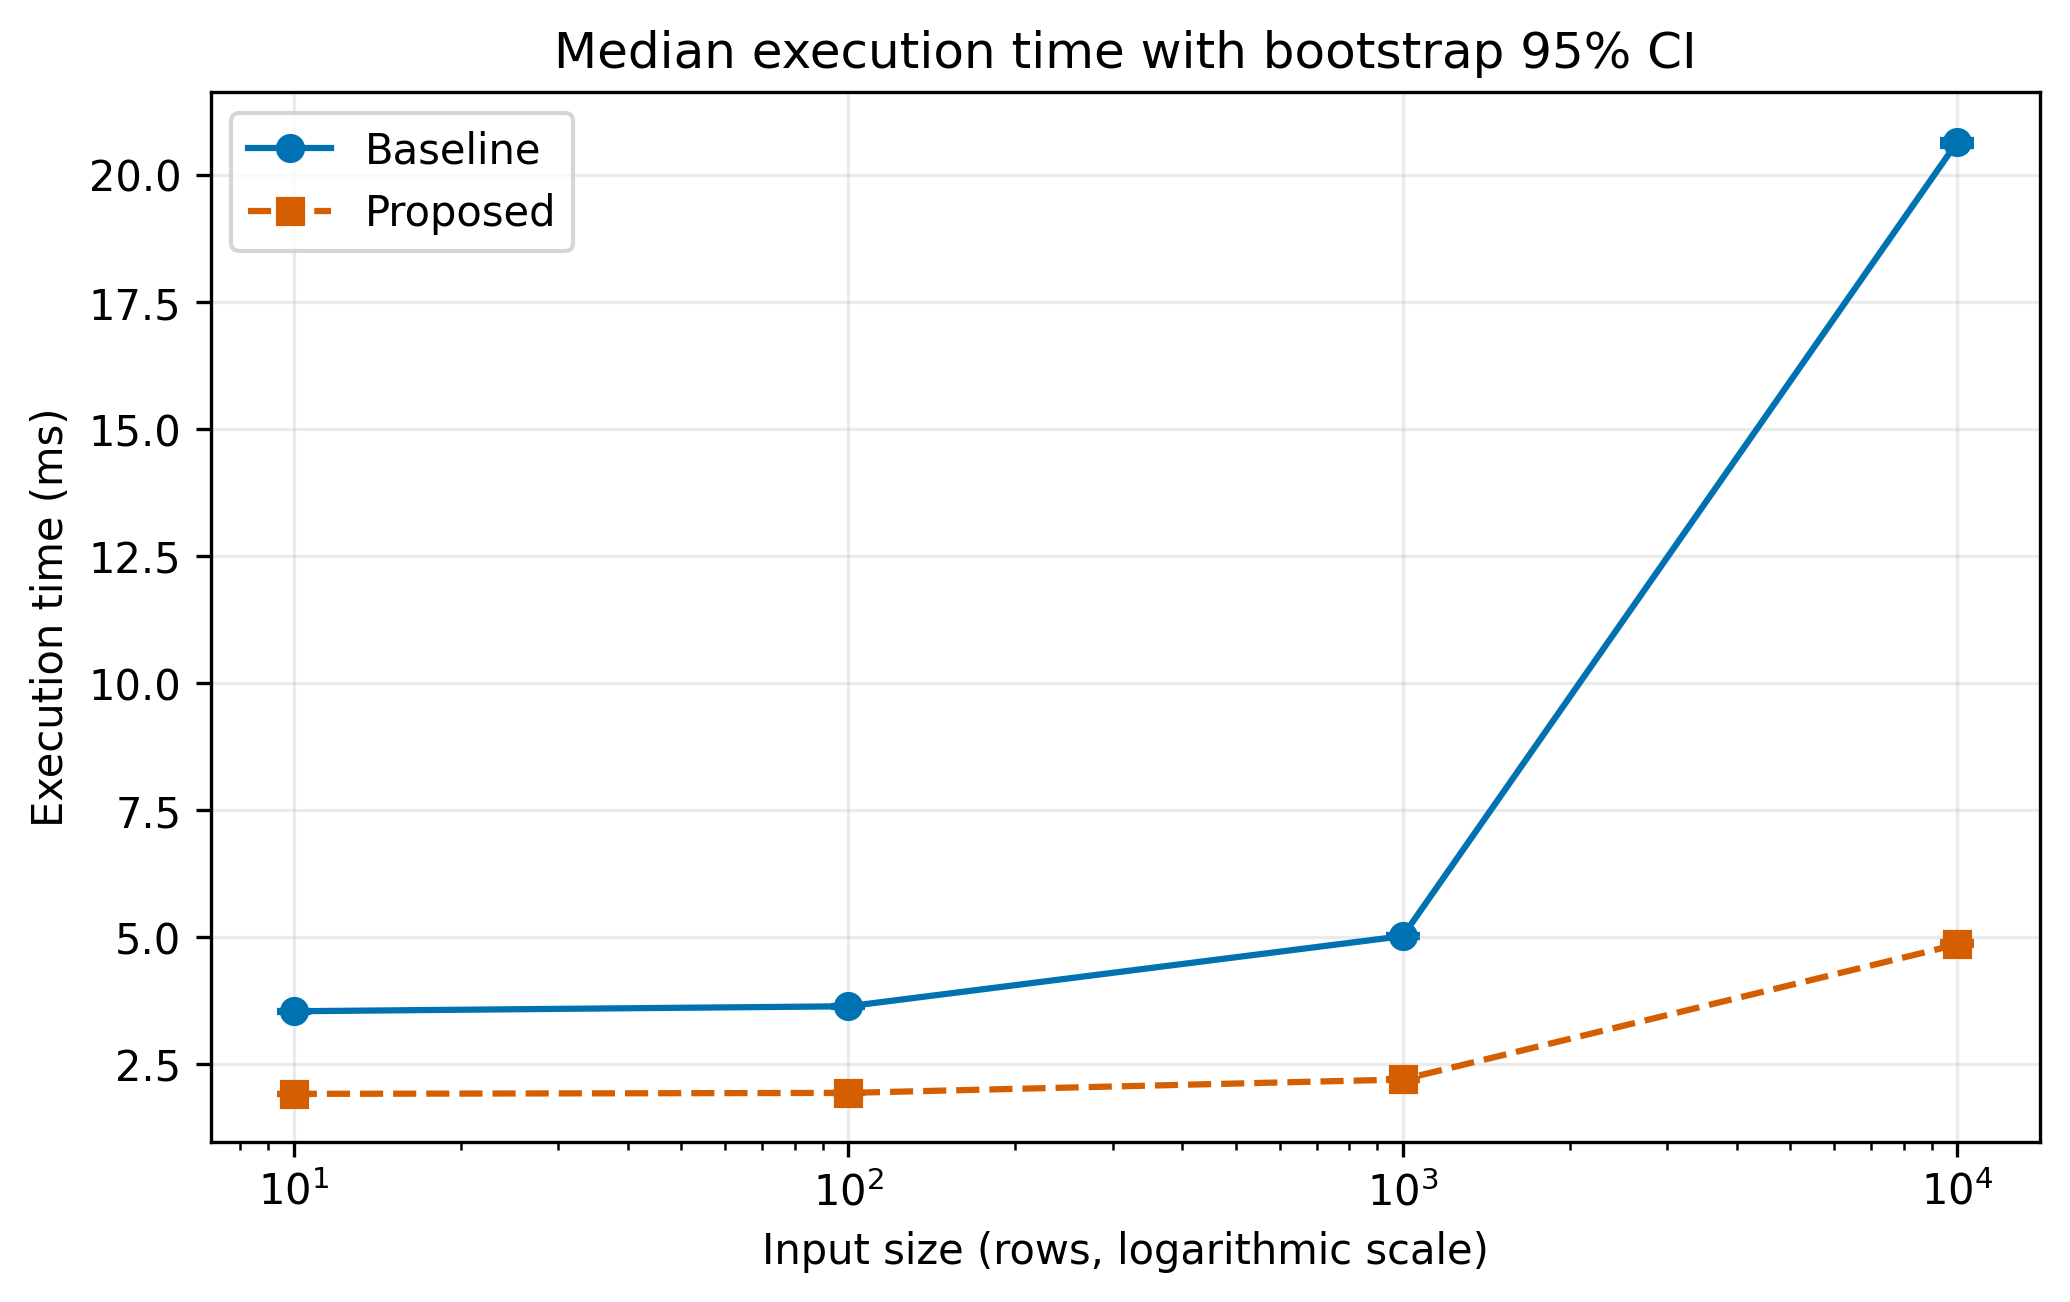

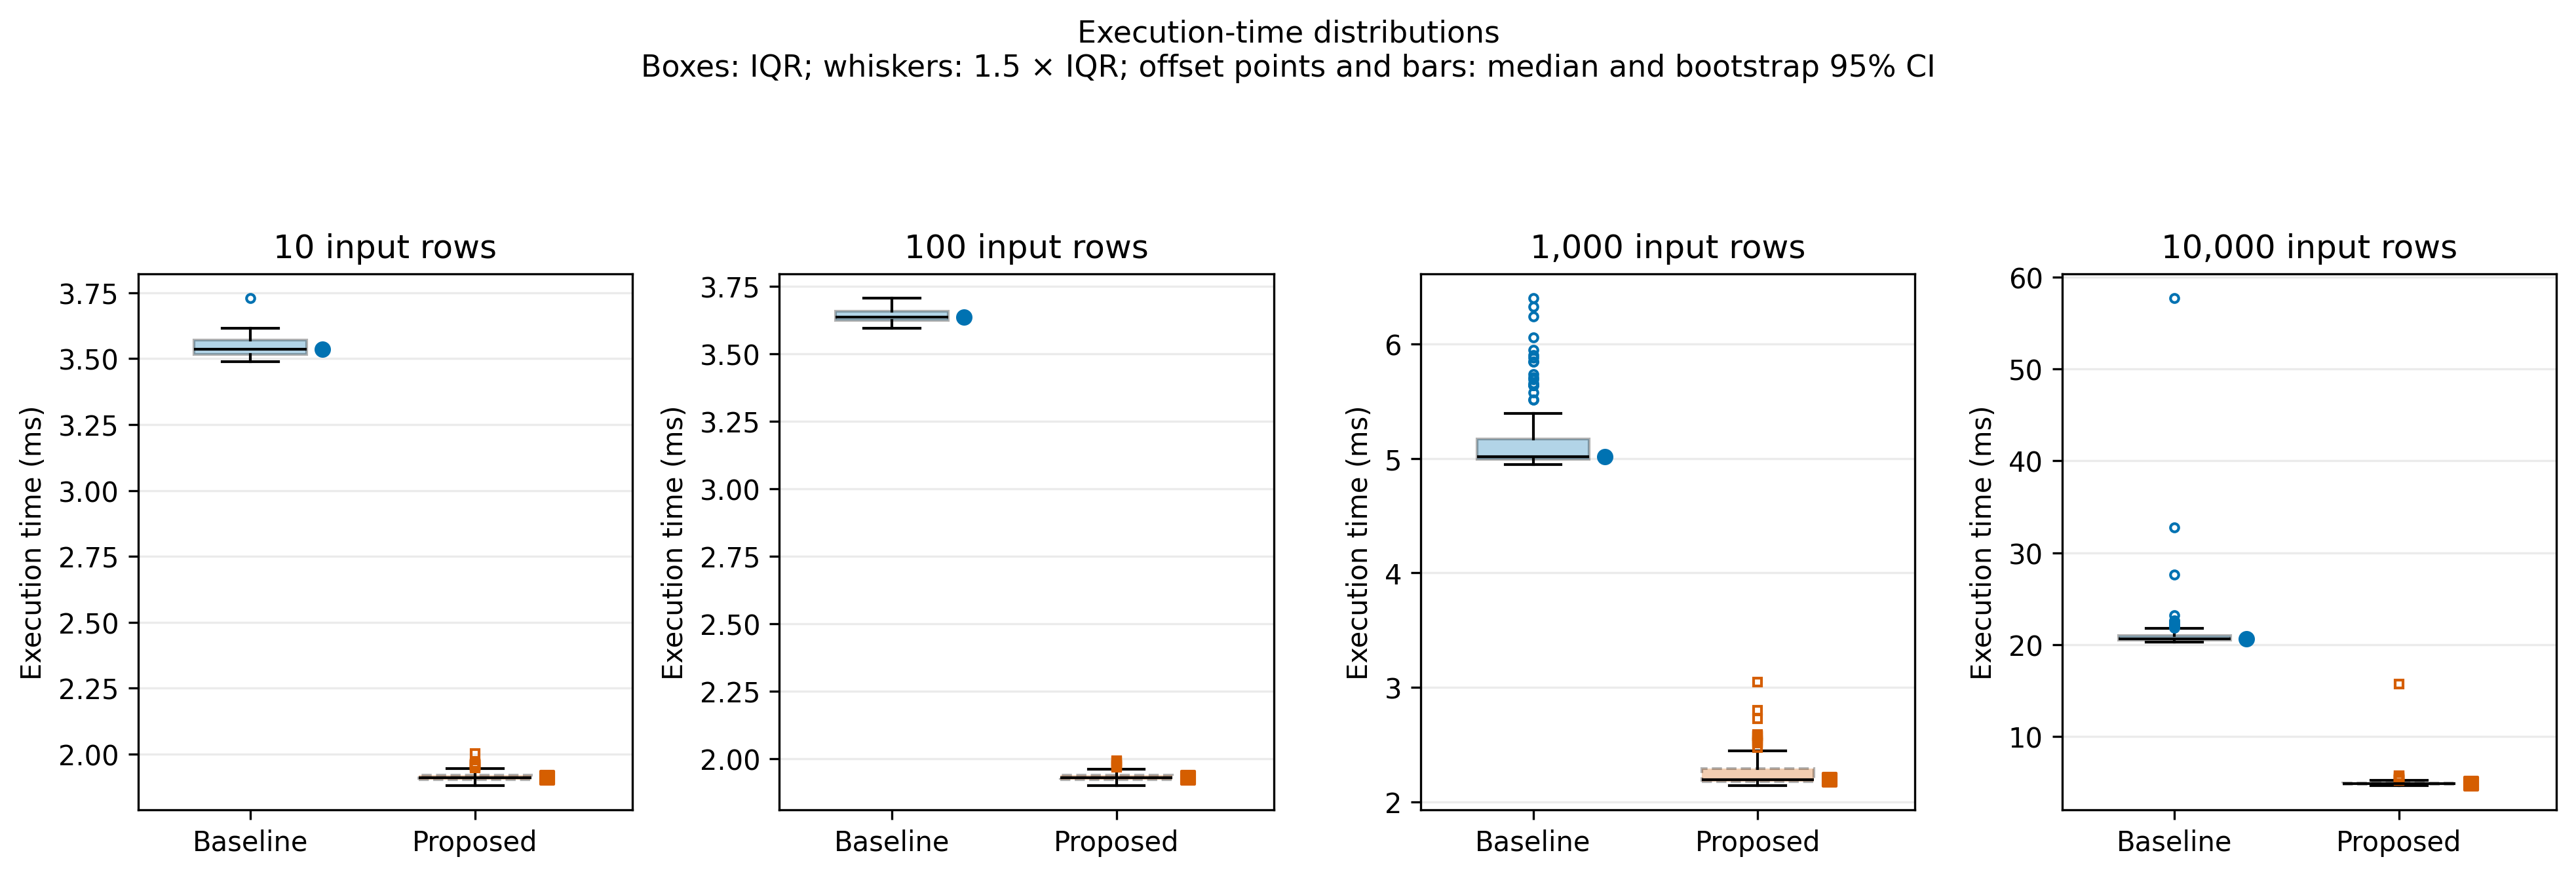

Figures saved in PNG and PDF formats.


In [4]:
from IPython.display import display, Image

figures_dir = ROOT / "reports/figures"

figures = create_figures(
    measured,
    summary,
    figures_dir,
)

for fig in figures:
    plt.close(fig)

display(Image(filename=str(
    figures_dir / "fig1_latency_vs_load.png"
)))

display(Image(filename=str(
    figures_dir / "fig2_distribution_boxplot.png"
)))

print("Figures saved in PNG and PDF formats.")

### Visualization

The first figure compares median execution time across input sizes.
Vertical bars show bootstrap 95% confidence intervals for the median.
The input-size axis uses a logarithmic scale.

The second figure shows execution-time distributions for each method
and input size. Boxes represent the interquartile range; whiskers
extend to the most extreme observations within 1.5 IQR of the box.
Points beyond the whiskers are retained as outliers.
Offset markers and bars show medians and their bootstrap 95% CIs.
Each panel uses its own vertical scale.

Both figures use colorblind-safe colors and distinct line styles
or markers. Figures are exported as vector PDF and 300 DPI PNG.

In [5]:
comparison = summary.pivot(
    index="input_rows",
    columns="method",
    values="median_ms",
)

comparison["speedup"] = (
    comparison["baseline"] / comparison["proposed"]
)

comparison = comparison.rename(columns={
    "baseline": "Baseline median (ms)",
    "proposed": "Proposed median (ms)",
    "speedup": "Speedup (times)",
})

display(comparison.round(3))

method,Baseline median (ms),Proposed median (ms),Speedup (times)
input_rows,,,
10,3.537,1.910,1.851
100,3.635,1.929,1.884
1000,5.016,2.193,2.287
10000,20.647,4.852,4.255


### Results and limitations

The proposed aggregation method had lower median execution time
at all four tested input sizes. At 10,000 rows, the baseline median
was approximately 20.647 ms, compared with 4.852 ms for the proposed
method, corresponding to a 4.26-fold speedup.

Both methods produced matching outputs on every tested workload.
All 800 measured runs completed without errors.

These results concern computational performance on repeated synthetic
data in one session on one machine. They do not establish an association
between short-form video use and student procrastination.
Increasing input size also increased the number of participant groups;
these effects were not evaluated separately.